In [3]:
%reload_ext autoreload
%autoreload 2
from IPython.display import Math
from tqdm import tqdm
import sys
import os
from tqdm import tqdm
from dataclasses import dataclass
parent_path = os.path.abspath("..")
if parent_path not in sys.path:
    sys.path.append(parent_path)

# For a quick config:
# import logging
# logging.basicConfig(
#     format="%(asctime)s [%(levelname)s] [%(name)s]: %(message)s",
#     level=logging.DEBUG
# )

import matplotlib
import matplotlib.pyplot as plt
import seaborn as sns
import pandas as pd

import sympy
import numpy as np
import numpy.typing as npt
import typing
from typing import Callable, Dict, List, Optional, Tuple, Union, Iterable
import qutip # type: ignore

from src.quantum_utils import measure_povm
from src.quantum_utils import random_kets, random_density_matrices
from src.quantum_utils import QuantumStatesBatch, QuantumKetsBatch, QuantumOperatorsBatch, QuantumDensityMatricesBatch, QuantumState, QuantumKet, QuantumOperator, POVM
from src.povms import sic_povm, mub_povm, random_rank1_povm
from src.qelm_utils import exact_average_bias2, exact_average_estimator_variance

from src.shadow_tomography import frame_operator
from src.utils import pp_matrix
from src.QELM import QELM, TrainingData

def int_or_inf(x):
    return x if np.isposinf(x) else int(x)

def random_rank1_povm_generator(dim: int, num_outcomes: int, seed: int | None = None) -> Callable[[], POVM]:
    def generator() -> POVM:
        return random_rank1_povm(dim=dim, num_outcomes=num_outcomes, seed=seed)
    return generator

# make a dataclass for the results of a QELM experiment, with fields: num_outcomes, what, dim, povm, target_observables, results
@dataclass
class QELMRunResults:
    num_outcomes: int
    what: str
    dim: int
    povm: POVM
    target_observables: QuantumOperator | QuantumOperatorsBatch
    n_realizations: int
    n_train_states: int
    n_test_states: int
    results: pd.DataFrame

def two_qubit_pauli_linear_combo(rnd_vec: np.ndarray) -> np.ndarray:
    """
    Build the 4x4 Hermitian operator:
        O = sum_{a,b in {I,X,Y,Z}} rnd_vec[idx(a,b)] * (sigma_a ⊗ sigma_b)

    Ordering (row-major over a then b):
      idx = 0..15 corresponds to:
      II, IX, IY, IZ, XI, XX, XY, XZ, YI, YX, YY, YZ, ZI, ZX, ZY, ZZ

    Returns:
      O as a (4,4) complex numpy array.
    """
    c = np.asarray(rnd_vec, dtype=float).ravel()
    if c.shape != (16,):
        raise ValueError(f"rnd_vec must have shape (16,), got {c.shape}")

    I = np.array([[1, 0], [0, 1]], dtype=complex)
    X = np.array([[0, 1], [1, 0]], dtype=complex)
    Y = np.array([[0, -1j], [1j, 0]], dtype=complex)
    Z = np.array([[1, 0], [0, -1]], dtype=complex)
    P = [I, X, Y, Z]

    # start with a 4x4 zero array so the accumulator is an ndarray, not int
    O = sum((c[4*a + b] * np.kron(P[a], P[b]) for a in range(4) for b in range(4)),
            start=np.zeros((4, 4), dtype=complex))
    return O

# ================= Helper function for QELM experiments =================
def run_qelm_experiment(
    stat_list: np.ndarray | List[Tuple[Union[int, float], Union[int, float]]],
    n_realizations: int,
    label: str,
    target_observables: QuantumOperator | QuantumOperatorsBatch,
    dim: int,
    num_outcomes: int,
    povm: POVM | Callable[[], POVM],
    train_states: int | Callable[[], QuantumStatesBatch],
    test_states: int | Callable[[], QuantumStatesBatch],
    post_processing_fn: Optional[Callable[[np.ndarray], np.ndarray]] = None,
    target_functional: Optional[Callable[[np.ndarray], np.ndarray]] = None,
    save_all: bool = False,
    compute_bias_var: bool = False
) -> QELMRunResults:
    """
    Run a QELM experiment with the given parameters.
        If a 1dim array, each element is used as both train_stat and test_stat.
        If a 2dim array or list of pairs, each element should be a pair (train_stat, test_stat).
    Args:
        stat_list: Array of statistics to sweep over

        n_realizations: Number of random realizations per stat
        label: Label for this experiment (e.g., "SWAP", "purity squaring")
        target_observables: Target observables for QELM (always used for initial predictions)
        dim: Dimension of quantum system
        num_outcomes: Number of outcomes for POVM
        povm: POVM measurement operator, or a callable that generates a POVM (if different POVMs are used for different realizations)
        train_states: Number of training states, or a callable that generates QuantumStatesBatch
        test_states: Number of test states, or a callable that generates QuantumStatesBatch
        post_processing_fn: Optional function to apply to the predictions before computing MSE
        target_functional: Optional function to compute target labels from the states (used with post_processing_fn)
        save_all: Whether to also save predictions and labels for all realizations (not just MSE)
        compute_bias_var: Whether to compute bias and variance of predictions (on top of the MSE)
    Returns:
        QELMRunResults: Dataclass containing the results of the experiment
    """
    results = []
    n_train_states_computed = 0
    n_test_states_computed = 0
    povm_ = None

    # if stat_list is 1D convert it to an array of pairs (stat, stat), otherwise we assume it's already an array of pairs (train_stat, test_stat)
    if isinstance(stat_list, np.ndarray) and stat_list.ndim == 1:
        stat_list = np.array([(int_or_inf(stat), int_or_inf(stat)) for stat in stat_list])
    # now stat_list is an array of pairs (train_stat, test_stat)
    for stat in tqdm(stat_list, desc="Statistics", leave=True):
        for _ in tqdm(range(n_realizations), desc="Realizations", leave=False):
            # initialize a dictionary to store results for this realization, we will append it to the results list at the end of the loop
            result = {}
            # if povm is a callable, call it to generate a POVM, othewrise use the provided POVM
            if callable(povm):
                povm_ = povm()
            else:
                povm_ = povm
            # if train_states is an integer generate random pure states, otherwise call the function
            if isinstance(train_states, int):
                train_states_ = QuantumKetsBatch(random_kets(dim=dim, num_kets=train_states))
                n_train_states_computed = train_states
            else:
                train_states_ = train_states()
                n_train_states_computed = len(train_states_)
            # if test_states is an integer generate random pure states, otherwise call the function
            if isinstance(test_states, int):
                test_states_ = QuantumKetsBatch(random_kets(dim=dim, num_kets=test_states))
                n_test_states_computed = test_states
            else:
                test_states_ = test_states()
                n_test_states_computed = len(test_states_)
            # compute train and test frequencies
            train_frequencies = train_states_.measure_povm(povm_, statistics=stat[0], return_frequencies=True)
            test_frequencies = test_states_.measure_povm(povm_, statistics=stat[1], return_frequencies=True)
            
            # Always compute labels from target observables
            train_labels = train_states_.expvals(observables=target_observables)
            test_labels = test_states_.expvals(observables=target_observables)
            # prepare data for training and testing the QELM
            train_data = TrainingData(frequencies=train_frequencies, labels=train_labels)
            test_data = TrainingData(frequencies=test_frequencies, labels=test_labels)
            # train and evaluate the QELM
            qelm = QELM(train=train_data, test=test_data)
            qelm.compute_MSE(train=True, test=True, display_results=False)
            
            # If both post_processing_fn and target_functional are provided, apply post-processing
            if post_processing_fn is not None and target_functional is not None:
                assert qelm.train_predictions is not None and qelm.test_predictions is not None, "QELM predictions must be computed before post-processing"
                
                # Apply post-processing to the predicted observable expectation values
                train_pred_processed = post_processing_fn(qelm.train_predictions)
                test_pred_processed = post_processing_fn(qelm.test_predictions)

                # Compute ground truth labels using the target functional
                train_labels = target_functional(train_states_.data)
                test_labels = target_functional(test_states_.data)
                
                # Compute MSE between post-processed predictions and functional labels
                train_mse = np.mean((train_pred_processed - train_labels)**2)
                test_mse = np.mean((test_pred_processed - test_labels)**2)
            else:
                # Otherwise use the standard QELM MSE (computed on observable expectation values)
                # we return a single value for MSE since we are only interested in one observable                
                train_mse = qelm.train_MSE[0]
                test_mse = qelm.test_MSE[0]

                train_pred_processed = qelm.train_predictions
                test_pred_processed = qelm.test_predictions

                if compute_bias_var:
                    estimator = qelm.w
                    # if target_observables is a batch, we compute bias and variance for each observable and save them in a list,
                    # otherwise we compute bias and variance for the single observable
                    if isinstance(target_observables, QuantumOperatorsBatch):
                        bias2 = []
                        variance = []
                        for i in range(len(target_observables)):
                            obs = QuantumOperator(target_observables[i])
                            bias2.append(exact_average_bias2(estimator=estimator[i], povm=povm_, target_observable=obs))
                            variance.append(exact_average_estimator_variance(estimator=estimator[i], povm=povm_))
                    else:
                        bias2 = exact_average_bias2(estimator=estimator[0], povm=povm_, target_observable=target_observables)
                        variance = exact_average_estimator_variance(estimator=estimator[0], povm=povm_)
                    result.update({
                        "bias2": bias2,
                        "variance": variance
                    })
            # save results
            if save_all:
                result.update({
                    "train_stat": stat[0],
                    "test_stat": stat[1],
                    "train_mse": train_mse,
                    "test_mse": test_mse,
                    "train_predictions": train_pred_processed,
                    "test_predictions": test_pred_processed,
                    "train_labels": train_labels,
                    "test_labels": test_labels
                })
            else:
                result.update({
                    "train_stat": stat[0],
                    "test_stat": stat[1],
                    "train_mse": train_mse,
                    "test_mse": test_mse
                })
            results.append(result)
    assert povm_ is not None, "POVM was not generated during the experiment, check the povm argument"
    # save results in the dataclass QELMRunResults
    qelm_run_results = QELMRunResults(
        num_outcomes=num_outcomes,
        what=label,
        dim=dim,
        povm=povm_,
        target_observables=target_observables,
        n_realizations=n_realizations,
        n_train_states=n_train_states_computed,
        n_test_states=n_test_states_computed,
        results=pd.DataFrame(results)
    )
    return qelm_run_results

# Use pairs of random mixed states for training

In [ ]:
def compute_purity_from_bloch_vectors(predictions: np.ndarray) -> np.ndarray:
    return (predictions[0, :]**2 + predictions[1, :]**2 + predictions[2, :]**2 + 1) / 2
swap_matrix = np.array([[1, 0, 0, 0],
                        [0, 0, 1, 0],
                        [0, 1, 0, 0],
                        [0, 0, 0, 1]])

n_train_states = 200
n_realizations = 200
stat_list=np.unique(np.logspace(1, 4, endpoint=False, num=20, base=10, dtype=int))
# generator for pairs of MIXED states of the form rho ⊗ rho, where rho is a random 1-qubit density matrix
def pairs_of_states_generator() -> QuantumStatesBatch:
    random_dms = random_density_matrices(n=n_train_states, dim=2)
    return QuantumDensityMatricesBatch([np.kron(dm, dm) for dm in random_dms])
def mixed_1qubit_states_generator() -> QuantumStatesBatch:
    random_dms = random_density_matrices(n=n_train_states, dim=2)
    return QuantumDensityMatricesBatch(random_dms)


n_outcomes = 10
data10outs = []

data10outs.append(run_qelm_experiment(
    stat_list=stat_list,
    n_realizations=n_realizations,
    label="purity squaring",
    target_observables=QuantumOperatorsBatch([op.full() for op in [qutip.sigmax(), qutip.sigmay(), qutip.sigmaz()]]),
    dim=2,
    num_outcomes=n_outcomes,
    povm=random_rank1_povm(dim=2, num_outcomes=n_outcomes),
    train_states=mixed_1qubit_states_generator, test_states=mixed_1qubit_states_generator,
    post_processing_fn=compute_purity_from_bloch_vectors,
    target_functional=lambda states: np.array([np.trace(state @ state).real for state in states])
))

data10outs.append(run_qelm_experiment(
    stat_list=stat_list,
    n_realizations=n_realizations,
    label="SWAP",
    target_observables=QuantumOperator(swap_matrix),
    dim=4,
    num_outcomes=n_outcomes,
    povm=random_rank1_povm(dim=4, num_outcomes=n_outcomes, seed=0),
    train_states=pairs_of_states_generator, test_states=pairs_of_states_generator
))

n_outcomes = 20
data20outs = []

data20outs.append(run_qelm_experiment(
    stat_list=stat_list,
    n_realizations=n_realizations,
    label="purity squaring",
    target_observables=QuantumOperatorsBatch([op.full() for op in [qutip.sigmax(), qutip.sigmay(), qutip.sigmaz()]]),
    dim=2,
    num_outcomes=n_outcomes,
    povm=random_rank1_povm(dim=2, num_outcomes=n_outcomes),
    train_states=mixed_1qubit_states_generator, test_states=mixed_1qubit_states_generator,
    post_processing_fn=compute_purity_from_bloch_vectors,
    target_functional=lambda states: np.array([np.trace(state @ state).real for state in states])
))

data20outs.append(run_qelm_experiment(
    stat_list=stat_list,
    n_realizations=n_realizations,
    label="SWAP",
    target_observables=QuantumOperator(swap_matrix),
    dim=4,
    num_outcomes=n_outcomes,
    povm=random_rank1_povm(dim=4, num_outcomes=n_outcomes, seed=0),
    train_states=pairs_of_states_generator, test_states=pairs_of_states_generator
))

n_outcomes = 40
data40outs = []

data40outs.append(run_qelm_experiment(
    stat_list=stat_list,
    n_realizations=n_realizations,
    label="purity squaring",
    target_observables=QuantumOperatorsBatch([op.full() for op in [qutip.sigmax(), qutip.sigmay(), qutip.sigmaz()]]),
    dim=2,
    num_outcomes=n_outcomes,
    povm=random_rank1_povm(dim=2, num_outcomes=n_outcomes),
    train_states=mixed_1qubit_states_generator, test_states=mixed_1qubit_states_generator,
    post_processing_fn=compute_purity_from_bloch_vectors,
    target_functional=lambda states: np.array([np.trace(state @ state).real for state in states])
))

data40outs.append(run_qelm_experiment(
    stat_list=stat_list,
    n_realizations=n_realizations,
    label="SWAP",
    target_observables=QuantumOperator(swap_matrix),
    dim=4,
    num_outcomes=n_outcomes,
    povm=random_rank1_povm(dim=4, num_outcomes=n_outcomes, seed=0),
    train_states=pairs_of_states_generator, test_states=pairs_of_states_generator
))

Train statistics: 100%|██████████| 20/20 [00:30<00:00,  1.51s/it]


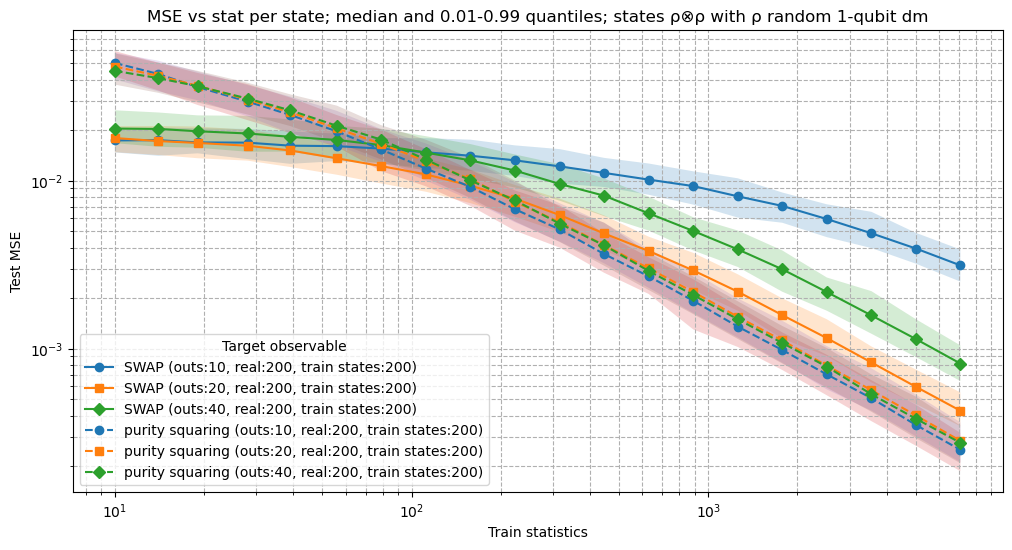

In [ ]:
# aggregate all data in the results list of dataclass QELMRunResults, and plot the MSE computed in each case (as median with quantiles)
# take care to use separate legends and title specifying all necessary information for each case
aggregated_results = []
for data_ in  data10outs + data20outs + data40outs:
    df = data_.results.copy()
    df["what"] = data_.what
    df["num_outcomes"] = data_.num_outcomes
    df["dim"] = data_.dim
    df["n_realizations"] = data_.n_realizations
    df["n_train_states"] = data_.n_train_states
    aggregated_results.append(df)
# now go with the plotting
aggregated_results_df = pd.concat(aggregated_results, ignore_index=True)

# compute median and quantiles for each group
summary_df = (
    aggregated_results_df
    .groupby(["train_stat", "what", "num_outcomes"], as_index=False)
    .agg(
        test_mse_median=("test_mse", "median"),
        test_mse_qmin=("test_mse", lambda x: x.quantile(0.01)),
        test_mse_qmax=("test_mse", lambda x: x.quantile(0.99)),
        num_outcomes=("num_outcomes", "first"),
        n_realizations=("n_realizations", "first"),
        n_train_states=("n_train_states", "first"),
    )
)

plt.figure(figsize=(12, 6))
whats = sorted(summary_df["what"].unique())
style_map = {what: style for what, style in zip(whats, ["-", "--"])}
num_outcomes_values = sorted(summary_df["num_outcomes"].unique())
colors = plt.rcParams["axes.prop_cycle"].by_key()["color"]
markers = ["o", "s", "D", "^", "v", "P", "X", "*"]
color_map = {what: colors[i % len(colors)] for i, what in enumerate(whats)}
marker_map = {num: markers[i % len(markers)] for i, num in enumerate(num_outcomes_values)}
for what in summary_df["what"].unique():
    subset = summary_df[summary_df["what"] == what]
    for num_outcomes in subset["num_outcomes"].unique():
        subset_outcomes = subset[subset["num_outcomes"] == num_outcomes]
        n_realizations = subset_outcomes["n_realizations"].iloc[0]
        n_train_states = subset_outcomes["n_train_states"].iloc[0]
        label_text = f"{what} (outs:{num_outcomes}, real:{n_realizations}, train states:{n_train_states})"
        plt.plot(
            subset_outcomes["train_stat"],
            subset_outcomes["test_mse_median"],
            marker=marker_map.get(num_outcomes, "o"),
            linestyle=style_map.get(what, "-"),
            color=color_map.get(what),
            label=label_text,
        )
        plt.fill_between(subset_outcomes["train_stat"], subset_outcomes["test_mse_qmin"], subset_outcomes["test_mse_qmax"], alpha=0.2)


plt.xscale("log")
plt.yscale("log")
plt.xlabel("Train statistics")
plt.ylabel("Test MSE")
plt.title("MSE vs stat per state; median and 0.01-0.99 quantiles; states ρ⊗ρ with ρ random 1-qubit dm")
plt.legend(title="Target observable")
plt.grid(True, which="both", ls="--")
# plt.tight_layout()
plt.show()

# Same shit but with fully random states in train and test

Generate the data. Here fully random *pure* states are used in train and test

In [ ]:
def compute_purity_from_bloch_vectors(predictions: np.ndarray) -> np.ndarray:
    return (predictions[0, :]**2 + predictions[1, :]**2 + predictions[2, :]**2 + 1) / 2
swap_matrix = np.array([[1, 0, 0, 0],
                        [0, 0, 1, 0],
                        [0, 1, 0, 0],
                        [0, 0, 0, 1]])

n_train_states = 200
n_outcomes = 20
n_realizations = 100

data20outs_fullrnd = []

data20outs_fullrnd.append(run_qelm_experiment(
    stat_list=np.unique(np.logspace(1, 6, endpoint=False, num=20, base=10, dtype=int)),
    n_realizations=n_realizations,
    label="purity squaring",
    target_observables=QuantumOperatorsBatch([op.full() for op in [qutip.sigmax(), qutip.sigmay(), qutip.sigmaz()]]),
    dim=2,
    num_outcomes=n_outcomes,
    povm=random_rank1_povm(dim=2, num_outcomes=n_outcomes),
    train_states=n_train_states, test_states=n_train_states,
    post_processing_fn=compute_purity_from_bloch_vectors,
    target_functional=lambda states: np.ones((states.shape[0], 1))
))

data20outs_fullrnd.append(run_qelm_experiment(
    stat_list=np.unique(np.logspace(1, 6, endpoint=False, num=20, base=10, dtype=int)),
    n_realizations=n_realizations,
    label="SWAP",
    target_observables=QuantumOperator(swap_matrix),
    dim=4,
    num_outcomes=n_outcomes,
    povm=random_rank1_povm(dim=4, num_outcomes=n_outcomes, seed=0),
    train_states=n_train_states, test_states=n_train_states,
))


data40outs_fullrnd = []
n_outcomes = 40

data40outs_fullrnd.append(run_qelm_experiment(
    stat_list=np.unique(np.logspace(1, 6, endpoint=False, num=20, base=10, dtype=int)),
    n_realizations=n_realizations,
    label="purity squaring",
    target_observables=QuantumOperatorsBatch([op.full() for op in [qutip.sigmax(), qutip.sigmay(), qutip.sigmaz()]]),
    dim=2,
    num_outcomes=n_outcomes,
    povm=random_rank1_povm(dim=2, num_outcomes=n_outcomes),
    train_states=n_train_states, test_states=n_train_states,
    post_processing_fn=compute_purity_from_bloch_vectors,
    target_functional=lambda states: np.ones((states.shape[0], 1))
))

data40outs_fullrnd.append(run_qelm_experiment(
    stat_list=np.unique(np.logspace(1, 6, endpoint=False, num=20, base=10, dtype=int)),
    n_realizations=n_realizations,
    label="SWAP",
    target_observables=QuantumOperator(swap_matrix),
    dim=4,
    num_outcomes=n_outcomes,
    povm=random_rank1_povm(dim=4, num_outcomes=n_outcomes, seed=0),
    train_states=n_train_states, test_states=n_train_states,
))


Train statistics: 100%|██████████| 20/20 [00:08<00:00,  2.28it/s]


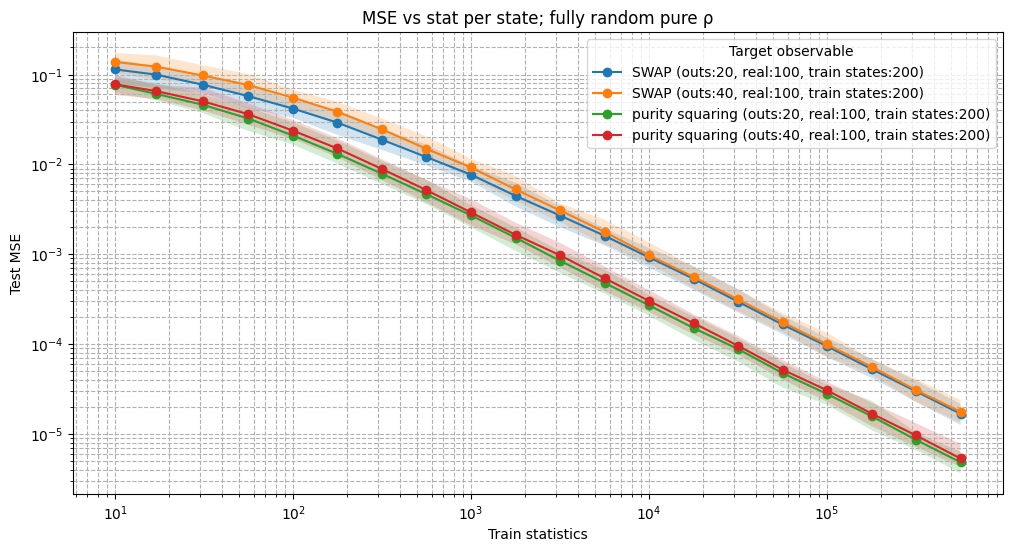

In [ ]:
# aggregate all data in the results list of dataclass QELMRunResults, and plot the MSE computed in each case (as median with quantiles)
# take care to use separate legends and title specifying all necessary information for each case
aggregated_results = []
for data_ in data20outs_fullrnd + data40outs_fullrnd:
    df = data_.results.copy()
    df["what"] = data_.what
    df["num_outcomes"] = data_.num_outcomes
    df["dim"] = data_.dim
    df["n_realizations"] = data_.n_realizations
    df["n_train_states"] = data_.n_train_states
    aggregated_results.append(df)
# now go with the plotting
aggregated_results_df = pd.concat(aggregated_results, ignore_index=True)

# compute median and quantiles for each group
summary_df = (
    aggregated_results_df
    .groupby(["train_stat", "what", "num_outcomes"], as_index=False)
    .agg(
        test_mse_median=("test_mse", "median"),
        test_mse_qmin=("test_mse", lambda x: x.quantile(0)),
        test_mse_qmax=("test_mse", lambda x: x.quantile(1)),
        num_outcomes=("num_outcomes", "first"),
        n_realizations=("n_realizations", "first"),
        n_train_states=("n_train_states", "first"),
    )
)

plt.figure(figsize=(12, 6))
whats = sorted(summary_df["what"].unique())
style_map = {what: style for what, style in zip(whats, ["-", "--"])}
num_outcomes_values = sorted(summary_df["num_outcomes"].unique())
colors = plt.rcParams["axes.prop_cycle"].by_key()["color"]
markers = ["o", "s", "D", "^", "v", "P", "X", "*"]
color_map = {num: colors[i % len(colors)] for i, num in enumerate(num_outcomes_values)}
marker_map = {num: markers[i % len(markers)] for i, num in enumerate(num_outcomes_values)}
for what in summary_df["what"].unique():
    subset = summary_df[summary_df["what"] == what]
    for num_outcomes in subset["num_outcomes"].unique():
        subset_outcomes = subset[subset["num_outcomes"] == num_outcomes]
        n_realizations = subset_outcomes["n_realizations"].iloc[0]
        n_train_states = subset_outcomes["n_train_states"].iloc[0]
        label_text = f"{what} (outs:{num_outcomes}, real:{n_realizations}, train states:{n_train_states})"
        plt.plot(
            subset_outcomes["train_stat"],
            subset_outcomes["test_mse_median"],
            marker=marker_map.get(num_outcomes, "o"),
            linestyle=style_map.get(what, "-"),
            color=color_map.get(num_outcomes),
            label=label_text,
        )
        plt.fill_between(subset_outcomes["train_stat"], subset_outcomes["test_mse_qmin"], subset_outcomes["test_mse_qmax"], alpha=0.2)


plt.xscale("log")
plt.yscale("log")
plt.xlabel("Train statistics")
plt.ylabel("Test MSE")
plt.title("MSE vs stat per state; fully random pure ρ")
plt.legend(title="Target observable")
plt.grid(True, which="both", ls="--")
# plt.tight_layout()
plt.show()

# Comparing $\langle XX\rangle$ VS $\langle X\rangle^2$

In [ ]:
def compute_Xsq(predictions: np.ndarray) -> np.ndarray:
    return predictions[0, :]**2

n_train_states = 200
n_realizations = 200
train_stat_list=np.unique(np.logspace(1, 3, endpoint=False, num=20, base=10, dtype=int))
# generator for pairs of MIXED states of the form rho ⊗ rho, where rho is a random 1-qubit density matrix
def pairs_of_states_generator() -> QuantumStatesBatch:
    random_dms = random_density_matrices(n=n_train_states, dim=2)
    return QuantumDensityMatricesBatch([np.kron(dm, dm) for dm in random_dms])
def mixed_1qubit_states_generator() -> QuantumStatesBatch:
    random_dms = random_density_matrices(n=n_train_states, dim=2)
    return QuantumDensityMatricesBatch(random_dms)
def random_rank1_povm_generator(dim: int, num_outcomes: int, seed: int | None = None) -> Callable[[], POVM]:
    def generator() -> POVM:
        return random_rank1_povm(dim=dim, num_outcomes=num_outcomes, seed=seed)
    return generator

dataXsq = []

n_outcomes = 20
dataXsq.append(run_qelm_experiment(
    stat_list=train_stat_list,
    n_realizations=n_realizations,
    label=r"$\langle X\rangle^2$, mixed states",
    target_observables=QuantumOperator(qutip.sigmax().full()),
    dim=2,
    num_outcomes=n_outcomes,
    povm=random_rank1_povm_generator(dim=2, num_outcomes=n_outcomes),
    train_states=mixed_1qubit_states_generator, test_states=mixed_1qubit_states_generator,
    post_processing_fn=compute_Xsq,
    target_functional=lambda states: np.array([np.trace(state @ qutip.sigmax().full()).real**2 for state in states])
))

dataXsq.append(run_qelm_experiment(
    stat_list=train_stat_list,
    n_realizations=n_realizations,
    label=r"$\langle X\rangle^2$, pure states",
    target_observables=QuantumOperator(qutip.sigmax().full()),
    dim=2,
    num_outcomes=n_outcomes,
    povm=random_rank1_povm_generator(dim=2, num_outcomes=n_outcomes),
    train_states=mixed_1qubit_states_generator, test_states=mixed_1qubit_states_generator,
    post_processing_fn=compute_Xsq,
    target_functional=lambda states: np.array([np.trace(state @ qutip.sigmax().full()).real**2 for state in states])
))

dataXsq.append(run_qelm_experiment(
    stat_list=train_stat_list,
    n_realizations=n_realizations,
    label=r"$\langle XX\rangle$, states $\rho\otimes\rho$",
    target_observables=QuantumOperator(qutip.tensor(qutip.sigmax(), qutip.sigmax()).full()),
    dim=4,
    num_outcomes=n_outcomes,
    povm=random_rank1_povm_generator(dim=4, num_outcomes=n_outcomes),
    train_states=pairs_of_states_generator, test_states=pairs_of_states_generator
))

dataXsq.append(run_qelm_experiment(
    stat_list=train_stat_list,
    n_realizations=n_realizations,
    label=r"$\langle XX\rangle$, random pure states",
    target_observables=QuantumOperator(qutip.tensor(qutip.sigmax(), qutip.sigmax()).full()),
    dim=4,
    num_outcomes=n_outcomes,
    povm=random_rank1_povm_generator(dim=4, num_outcomes=n_outcomes),
    train_states=n_train_states, test_states=n_train_states
))

dataXsq.append(run_qelm_experiment(
    stat_list=train_stat_list,
    n_realizations=n_realizations,
    label=r"$\langle YZ\rangle$, random pure states",
    target_observables=QuantumOperator(qutip.tensor(qutip.sigmay(), qutip.sigmaz()).full()),
    dim=4,
    num_outcomes=n_outcomes,
    povm=random_rank1_povm_generator(dim=4, num_outcomes=n_outcomes),
    train_states=n_train_states, test_states=n_train_states
))

dataXsq.append(run_qelm_experiment(
    stat_list=train_stat_list,
    n_realizations=n_realizations,
    label=r"$\langle YY\rangle$, random pure states",
    target_observables=QuantumOperator(qutip.tensor(qutip.sigmay(), qutip.sigmay()).full()),
    dim=4,
    num_outcomes=n_outcomes,
    povm=random_rank1_povm_generator(dim=4, num_outcomes=n_outcomes),
    train_states=n_train_states, test_states=n_train_states
))

Train statistics: 100%|██████████| 20/20 [00:10<00:00,  1.98it/s]


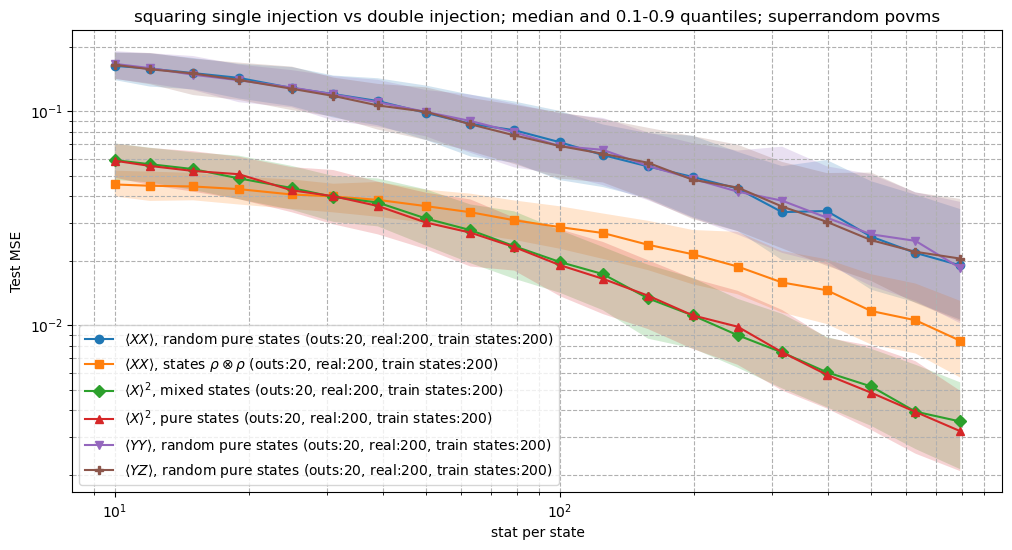

In [120]:
# aggregate all data in the results list of dataclass QELMRunResults, and plot the MSE computed in each case (as median with quantiles)
# take care to use separate legends and title specifying all necessary information for each case
aggregated_results = []
for data_ in dataXsq:
    df = data_.results.copy()
    df["what"] = data_.what
    df["num_outcomes"] = data_.num_outcomes
    df["dim"] = data_.dim
    df["n_realizations"] = data_.n_realizations
    df["n_train_states"] = data_.n_train_states
    aggregated_results.append(df)
# now go with the plotting
aggregated_results_df = pd.concat(aggregated_results, ignore_index=True)

# compute median and quantiles for each group
summary_df = (
    aggregated_results_df
    .groupby(["train_stat", "what", "num_outcomes"], as_index=False)
    .agg(
        test_mse_median=("test_mse", "median"),
        test_mse_qmin=("test_mse", lambda x: x.quantile(0.1)),
        test_mse_qmax=("test_mse", lambda x: x.quantile(0.9)),
        num_outcomes=("num_outcomes", "first"),
        n_realizations=("n_realizations", "first"),
        n_train_states=("n_train_states", "first"),
    )
)

plt.figure(figsize=(12, 6))
whats = sorted(summary_df["what"].unique())
num_outcomes_values = sorted(summary_df["num_outcomes"].unique())
style_map = {num_outcomes: style for num_outcomes, style in zip(num_outcomes_values, ["-", "--"])}
colors = plt.rcParams["axes.prop_cycle"].by_key()["color"]
markers = ["o", "s", "D", "^", "v", "P", "X", "*"]
color_map = {what: colors[i % len(colors)] for i, what in enumerate(whats)}
marker_map = {what: markers[i % len(markers)] for i, what in enumerate(whats)}
for what in summary_df["what"].unique():
    subset = summary_df[summary_df["what"] == what]
    for num_outcomes in subset["num_outcomes"].unique():
        subset_outcomes = subset[subset["num_outcomes"] == num_outcomes]
        n_realizations = subset_outcomes["n_realizations"].iloc[0]
        n_train_states = subset_outcomes["n_train_states"].iloc[0]
        label_text = f"{what} (outs:{num_outcomes}, real:{n_realizations}, train states:{n_train_states})"
        plt.plot(
            subset_outcomes["train_stat"],
            subset_outcomes["test_mse_median"],
            marker=marker_map.get(what, "o"),
            linestyle=style_map.get(num_outcomes, "-"),
            color=color_map.get(what),
            label=label_text,
        )
        plt.fill_between(subset_outcomes["train_stat"], subset_outcomes["test_mse_qmin"], subset_outcomes["test_mse_qmax"], alpha=0.2)


plt.xscale("log")
plt.yscale("log")
plt.xlabel("stat per state")
plt.ylabel("Test MSE")
plt.title("squaring single injection vs double injection; median and 0.1-0.9 quantiles; superrandom povms")
plt.legend(title="")
plt.grid(True, which="both", ls="--")
# plt.tight_layout()
plt.show()

# Trying with target observables with more components

Using as targets observables with higher rank the difference between the two cases should be magnified. We *kinda* see it in the fact that the crossing moves on the right

In [30]:
# compute a random unit vector of length 16
rnd_vec = np.random.rand(15)
rnd_vec = rnd_vec / np.linalg.norm(rnd_vec)
rnd_vec *= np.sqrt(4 - 1)
rnd_vec = np.concatenate(([1], rnd_vec)) / 4
def compute_obs_in_postprocessing(predictions: np.ndarray) -> np.ndarray:
    """
    predictions: (3, N) rows are [<X>, <Y>, <Z>].

    Build v = [1, <X>, <Y>, <Z>] per state, form the 16 products v[a]*v[b]
    (a,b in {I,X,Y,Z} in row-major order), then take rnd_vec-weighted sum.
    Returns: (N,)
    """
    p = np.asarray(predictions, dtype=float)        # ensure float ndarray
    if p.ndim != 2 or p.shape[0] != 3:
        raise ValueError(f"expected shape (3, N), got {p.shape}")

    v = np.vstack([np.ones(p.shape[1]), p])         # (4, N): [1; <X>; <Y>; <Z>]
    feats = np.einsum("aN,bN->abN", v, v).reshape(16, -1)  # (16, N): all v[a]*v[b]
    return rnd_vec @ feats                          # (N,): sum_k rnd_vec[k] * feats[k, :]

def true_obs_in_postprocessing(states: np.ndarray) -> np.ndarray:
    """
    states: (N, 2, 2) density matrices or (N, 2) pure states

    Build v = [1, <X>, <Y>, <Z>] per state, form the 16 products v[a]*v[b]
    (a,b in {I,X,Y,Z} in row-major order), then take rnd_vec-weighted sum.
    Returns: (N,)
    """
    N = states.shape[0]
    v = np.zeros((4, N))
    v[0, :] = 1
    for i, op in enumerate([qutip.sigmax(), qutip.sigmay(), qutip.sigmaz()]):
        # if states are pure then states has shape (N, 2) and we can compute expvals as <\psi|O1|\psi> <\psi|O2|\psi>
        if states.ndim == 2:
            v[i+1, :] = np.einsum("ni,ij,nj->n", states.conj(), op.full(), states).real
        elif states.ndim == 3:
        # otherwise states has shape (N, 4, 4) and we compute expvals as Tr[rho O1] Tr[rho O2]
            v[i+1, :] = np.einsum("nij,ij->n", states, op.full().conj()).real
        else:
            raise ValueError(f"expected states of shape (N, 2, 2) or (N, 2), got {states.shape}")
    feats = np.einsum("aN,bN->abN", v, v).reshape(16, -1)  # (16, N): all v[a]*v[b]
    return rnd_vec @ feats                          # (N,): sum_k rnd_vec[k] * feats[k, :]

# now just compute the target observable for the 2-qubit injection case by taking a linear combination of 2-qubit pauli strings via rnd_vec
target_observable = two_qubit_pauli_linear_combo(rnd_vec)

n_train_states = 200
n_realizations = 50
dim=2
train_stat_list=np.unique(np.logspace(1, 3, endpoint=False, num=20, base=10, dtype=int))
stat_list = [(train_stat, np.inf) for train_stat in train_stat_list]
# generator for pairs of MIXED states of the form rho ⊗ rho, where rho is a random 1-qubit density matrix
def pairs_of_mixed_states_generator() -> QuantumStatesBatch:
    random_dms = random_density_matrices(n=n_train_states, dim=dim)
    return QuantumDensityMatricesBatch([np.kron(dm, dm) for dm in random_dms])
def pairs_of_pure_states_generator() -> QuantumStatesBatch:
    kets = random_kets(dim=dim, num_kets=n_train_states)
    return QuantumKetsBatch([np.kron(ket, ket) for ket in kets])
def mixed_1qubit_states_generator() -> QuantumStatesBatch:
    random_dms = random_density_matrices(n=n_train_states, dim=dim)
    return QuantumDensityMatricesBatch(random_dms)
def random_rank1_povm_generator(dim: int, num_outcomes: int, seed: int | None = None) -> Callable[[], POVM]:
    def generator() -> POVM:
        return random_rank1_povm(dim=dim, num_outcomes=num_outcomes, seed=seed)
    return generator

dataLongObs = []

n_outcomes = 10
dataLongObs.append(run_qelm_experiment(
    stat_list=stat_list,
    n_realizations=n_realizations,
    label=r"single inj, rnd 2-qubit obs, pure states",
    target_observables=QuantumOperatorsBatch([op.full() for op in [qutip.sigmax(), qutip.sigmay(), qutip.sigmaz()]]),
    dim=dim,
    num_outcomes=n_outcomes,
    povm=random_rank1_povm_generator(dim=dim, num_outcomes=n_outcomes),
    train_states=n_train_states, test_states=n_train_states,
    post_processing_fn=compute_obs_in_postprocessing,
    target_functional=true_obs_in_postprocessing
))

dataLongObs.append(run_qelm_experiment(
    stat_list=stat_list,
    n_realizations=n_realizations,
    label=r"double inj, mixed ρ⊗ρ states",
    target_observables=QuantumOperator(target_observable),
    dim=2 * dim,
    num_outcomes=n_outcomes,
    povm=random_rank1_povm_generator(dim=2 * dim, num_outcomes=n_outcomes),
    train_states=pairs_of_mixed_states_generator, test_states=pairs_of_mixed_states_generator
))

dataLongObs.append(run_qelm_experiment(
    stat_list=stat_list,
    n_realizations=n_realizations,
    label=r"double inj, pure ρ⊗ρ states",
    target_observables=QuantumOperator(target_observable),
    dim=2 * dim,
    num_outcomes=n_outcomes,
    povm=random_rank1_povm_generator(dim=2 * dim, num_outcomes=n_outcomes),
    train_states=pairs_of_pure_states_generator, test_states=pairs_of_pure_states_generator
))

dataLongObs.append(run_qelm_experiment(
    stat_list=stat_list,
    n_realizations=n_realizations,
    label=r"double inj, rnd pure states",
    target_observables=QuantumOperator(target_observable),
    dim=2 * dim,
    num_outcomes=n_outcomes,
    povm=random_rank1_povm_generator(dim=2 * dim, num_outcomes=n_outcomes),
    train_states=n_train_states, test_states=n_train_states
))

Statistics: 100%|██████████| 20/20 [00:02<00:00,  9.84it/s]


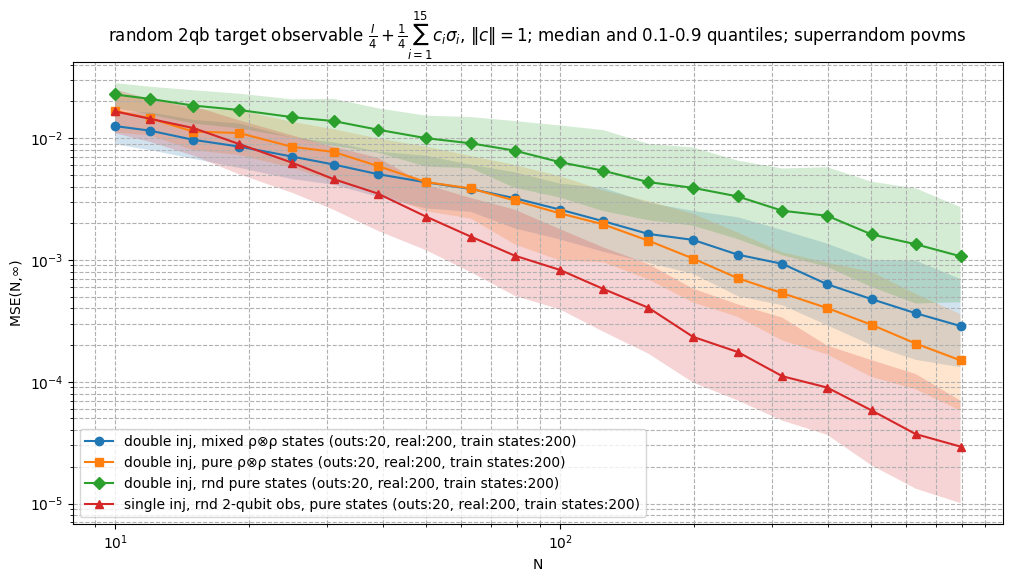

In [26]:
# aggregate all data in the results list of dataclass QELMRunResults, and plot the MSE computed in each case (as median with quantiles)
# take care to use separate legends and title specifying all necessary information for each case
aggregated_results = []
for data_ in dataLongObs:
    df = data_.results.copy()
    df["what"] = data_.what
    df["num_outcomes"] = data_.num_outcomes
    df["dim"] = data_.dim
    df["n_realizations"] = data_.n_realizations
    df["n_train_states"] = data_.n_train_states
    aggregated_results.append(df)
# now go with the plotting
aggregated_results_df = pd.concat(aggregated_results, ignore_index=True)

# compute median and quantiles for each group
summary_df = (
    aggregated_results_df
    .groupby(["train_stat", "what", "num_outcomes"], as_index=False)
    .agg(
        test_mse_median=("test_mse", "median"),
        test_mse_qmin=("test_mse", lambda x: x.quantile(0.1)),
        test_mse_qmax=("test_mse", lambda x: x.quantile(0.9)),
        num_outcomes=("num_outcomes", "first"),
        n_realizations=("n_realizations", "first"),
        n_train_states=("n_train_states", "first"),
    )
)

plt.figure(figsize=(12, 6))
whats = sorted(summary_df["what"].unique())
num_outcomes_values = sorted(summary_df["num_outcomes"].unique())
style_map = {num_outcomes: style for num_outcomes, style in zip(num_outcomes_values, ["-", "--"])}
colors = plt.rcParams["axes.prop_cycle"].by_key()["color"]
markers = ["o", "s", "D", "^", "v", "P", "X", "*"]
color_map = {what: colors[i % len(colors)] for i, what in enumerate(whats)}
marker_map = {what: markers[i % len(markers)] for i, what in enumerate(whats)}
for what in summary_df["what"].unique():
    subset = summary_df[summary_df["what"] == what]
    for num_outcomes in subset["num_outcomes"].unique():
        subset_outcomes = subset[subset["num_outcomes"] == num_outcomes]
        n_realizations = subset_outcomes["n_realizations"].iloc[0]
        n_train_states = subset_outcomes["n_train_states"].iloc[0]
        label_text = f"{what} (outs:{num_outcomes}, real:{n_realizations}, train states:{n_train_states})"
        plt.plot(
            subset_outcomes["train_stat"],
            subset_outcomes["test_mse_median"],
            marker=marker_map.get(what, "o"),
            linestyle=style_map.get(num_outcomes, "-"),
            color=color_map.get(what),
            label=label_text,
        )
        plt.fill_between(subset_outcomes["train_stat"], subset_outcomes["test_mse_qmin"], subset_outcomes["test_mse_qmax"], alpha=0.2)


plt.xscale("log")
plt.yscale("log")
plt.xlabel("N")
plt.ylabel(r"MSE(N,∞​​)")
plt.title(r"random 2qb target observable $\frac{I}{4}+\frac{1}{4}\sum_{i=1}^{15} c_i \sigma_i$, $\|c\|=1$; median and 0.1-0.9 quantiles; superrandom povms")
plt.legend(title="")
plt.grid(True, which="both", ls="--")
# plt.tight_layout()
plt.show()

# How does the error change increasing dimensions?

In [29]:
n_train_states = 200
n_realizations = 200
stat_list=np.unique(np.logspace(1, 6, endpoint=False, num=20, base=10, dtype=int))

dataVsDim = []

n_outcomes = 40
for dim in [2, 3, 4, 5, 6]:
    targetObs = qutip.ket2dm(qutip.basis(dim, 0)).full()
    dataVsDim.append(run_qelm_experiment(
        stat_list=stat_list,
        n_realizations=n_realizations,
        label=r"dim={dim}, pure states".format(dim=dim),
        target_observables=QuantumOperator(targetObs),
        dim=dim,
        num_outcomes=n_outcomes,
        povm=random_rank1_povm_generator(dim=dim, num_outcomes=n_outcomes),
        train_states=n_train_states, test_states=n_train_states,
        compute_bias_var=True
    ))


Statistics: 100%|██████████| 20/20 [05:41<00:00, 17.06s/it]


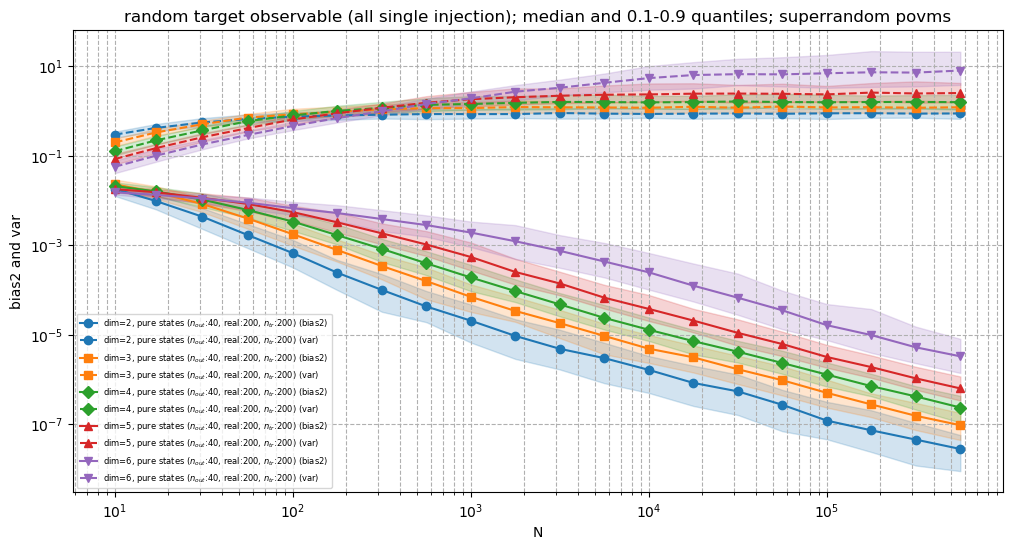

In [42]:
# aggregate all data in the results list of dataclass QELMRunResults, and plot the MSE computed in each case (as median with quantiles)
# take care to use separate legends and title specifying all necessary information for each case
aggregated_results = []
for data_ in dataVsDim:
    df = data_.results.copy()
    df["what"] = data_.what
    df["num_outcomes"] = data_.num_outcomes
    df["dim"] = data_.dim
    df["n_realizations"] = data_.n_realizations
    df["n_train_states"] = data_.n_train_states
    aggregated_results.append(df)
# now go with the plotting
aggregated_results_df = pd.concat(aggregated_results, ignore_index=True)

# compute median and quantiles for each group
summary_df = (
    aggregated_results_df
    .groupby(["train_stat", "what", "num_outcomes"], as_index=False)
    .agg(
        test_mse_median=("test_mse", "median"),
        test_mse_qmin=("test_mse", lambda x: x.quantile(0.1)),
        test_mse_qmax=("test_mse", lambda x: x.quantile(0.9)),
        bias2_median=("bias2", "median"),
        bias2_qmin=("bias2", lambda x: x.quantile(0.1)),
        bias2_qmax=("bias2", lambda x: x.quantile(0.9)),
        var_median=("variance", "median"),
        var_qmin=("variance", lambda x: x.quantile(0.1)),
        var_qmax=("variance", lambda x: x.quantile(0.9)),
        num_outcomes=("num_outcomes", "first"),
        n_realizations=("n_realizations", "first"),
        n_train_states=("n_train_states", "first"),
    )
)

plt.figure(figsize=(12, 6))
whats = sorted(summary_df["what"].unique())
num_outcomes_values = sorted(summary_df["num_outcomes"].unique())
style_map = {num_outcomes: style for num_outcomes, style in zip(num_outcomes_values, ["-", "--"])}
colors = plt.rcParams["axes.prop_cycle"].by_key()["color"]
markers = ["o", "s", "D", "^", "v", "P", "X", "*"]
color_map = {what: colors[i % len(colors)] for i, what in enumerate(whats)}
marker_map = {what: markers[i % len(markers)] for i, what in enumerate(whats)}
for what in summary_df["what"].unique():
    subset = summary_df[summary_df["what"] == what]
    for num_outcomes in subset["num_outcomes"].unique():
        subset_outcomes = subset[subset["num_outcomes"] == num_outcomes]
        n_realizations = subset_outcomes["n_realizations"].iloc[0]
        n_train_states = subset_outcomes["n_train_states"].iloc[0]
        label_text = f"{what} ($n_{{out}}$:{num_outcomes}, real:{n_realizations}, $n_{{tr}}$:{n_train_states})"
        plt.plot(
            subset_outcomes["train_stat"],
            subset_outcomes["bias2_median"],
            marker=marker_map.get(what, "o"),
            linestyle='-',
            color=color_map.get(what),
            label=f"{label_text} (bias2)",
        )
        plt.fill_between(subset_outcomes["train_stat"], subset_outcomes["bias2_qmin"], subset_outcomes["bias2_qmax"], alpha=0.2, color=color_map.get(what))
        plt.plot(
            subset_outcomes["train_stat"],
            subset_outcomes["var_median"],
            marker=marker_map.get(what, "o"),
            linestyle='--',
            color=color_map.get(what),
            label=f"{label_text} (var)",
        )
        plt.fill_between(subset_outcomes["train_stat"], subset_outcomes["var_qmin"], subset_outcomes["var_qmax"], alpha=0.2, color=color_map.get(what))


plt.xscale("log")
plt.yscale("log")
plt.xlabel("N")
plt.ylabel(r"bias2 and var")
plt.title(r"random target observable (all single injection); median and 0.1-0.9 quantiles; superrandom povms")
plt.legend(title="", fontsize=6)
plt.grid(True, which="both", ls="--")
# plt.tight_layout()
plt.show()

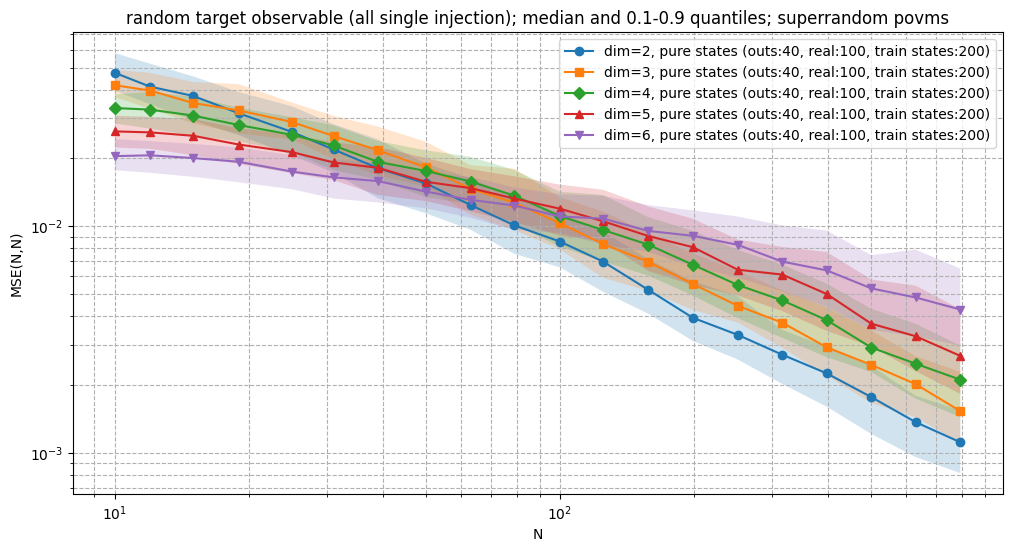

In [48]:
# aggregate all data in the results list of dataclass QELMRunResults, and plot the MSE computed in each case (as median with quantiles)
# take care to use separate legends and title specifying all necessary information for each case
aggregated_results = []
for data_ in dataVsDim:
    df = data_.results.copy()
    df["what"] = data_.what
    df["num_outcomes"] = data_.num_outcomes
    df["dim"] = data_.dim
    df["n_realizations"] = data_.n_realizations
    df["n_train_states"] = data_.n_train_states
    aggregated_results.append(df)
# now go with the plotting
aggregated_results_df = pd.concat(aggregated_results, ignore_index=True)

# compute median and quantiles for each group
summary_df = (
    aggregated_results_df
    .groupby(["train_stat", "what", "num_outcomes"], as_index=False)
    .agg(
        test_mse_median=("test_mse", "median"),
        test_mse_qmin=("test_mse", lambda x: x.quantile(0.1)),
        test_mse_qmax=("test_mse", lambda x: x.quantile(0.9)),
        num_outcomes=("num_outcomes", "first"),
        n_realizations=("n_realizations", "first"),
        n_train_states=("n_train_states", "first"),
    )
)

plt.figure(figsize=(12, 6))
whats = sorted(summary_df["what"].unique())
num_outcomes_values = sorted(summary_df["num_outcomes"].unique())
style_map = {num_outcomes: style for num_outcomes, style in zip(num_outcomes_values, ["-", "--"])}
colors = plt.rcParams["axes.prop_cycle"].by_key()["color"]
markers = ["o", "s", "D", "^", "v", "P", "X", "*"]
color_map = {what: colors[i % len(colors)] for i, what in enumerate(whats)}
marker_map = {what: markers[i % len(markers)] for i, what in enumerate(whats)}
for what in summary_df["what"].unique():
    subset = summary_df[summary_df["what"] == what]
    for num_outcomes in subset["num_outcomes"].unique():
        subset_outcomes = subset[subset["num_outcomes"] == num_outcomes]
        n_realizations = subset_outcomes["n_realizations"].iloc[0]
        n_train_states = subset_outcomes["n_train_states"].iloc[0]
        label_text = f"{what} (outs:{num_outcomes}, real:{n_realizations}, train states:{n_train_states})"
        plt.plot(
            subset_outcomes["train_stat"],
            subset_outcomes["test_mse_median"],
            marker=marker_map.get(what, "o"),
            linestyle=style_map.get(num_outcomes, "-"),
            color=color_map.get(what),
            label=label_text,
        )
        plt.fill_between(subset_outcomes["train_stat"], subset_outcomes["test_mse_qmin"], subset_outcomes["test_mse_qmax"], alpha=0.2)


plt.xscale("log")
plt.yscale("log")
plt.xlabel("N")
plt.ylabel(r"MSE(N,N)")
plt.title(r"random target observable (all single injection); median and 0.1-0.9 quantiles; superrandom povms")
plt.legend(title="")
plt.grid(True, which="both", ls="--")
# plt.tight_layout()
plt.show()